# Building an optimal portfolio system

1) Forecast (the big one)
2) Risk model (start with sample covariance matrix)
3) Cost model (start with only spread)

## Gathering Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[2] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../../../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-02"
END = "2026-06-02"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 59acd1f31c5cb651598f2b52e55c5b57.parquet
[GenericAdapter] scan_parquet: ae6e2e353449ba87c7db99ba2b04787b.parquet
[GenericAdapter] scan_parquet: 5ad4fa3280634d57059736634fa2bfe8.parquet


In [2]:
# daily volume before the final 10mins
session_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("SDV")
    )
    .sort("date")
)

avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).alias("ADV")
    )
    .drop("day_volume")
    .sort("date")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (
            (pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00") / 2))
        ).alias("spread_bps")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread_bps"]).last()
    )
    .rename({"price":"entry_price", "spread_bps":"spread_bps"})
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(session_dollar_volume, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .drop_nulls()
    .with_columns((pl.col("total_imbalance_qty") * pl.col("entry_price")).alias("dollar_imbalance"))
    .with_columns(
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("SDV"))
        ).alias("signed_session_imb_ratio"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("ADV"))
        ).alias("signed_mean_imb_ratio")
    )
    .drop(["total_imbalance_qty"])
).collect(engine="streaming")

# The dataframe we will be working with
data

date,symbol,side,entry_price,spread_bps,auction_price,SDV,ADV,dollar_imbalance,signed_session_imb_ratio,signed_mean_imb_ratio
date,cat,str,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-02,"""AAL""","""B""",11.335,0.000588,11.38,4.2328e7,8.3108e7,6.2903e6,0.148609,0.075688
2025-06-02,"""AAOI""","""A""",15.61,0.000427,15.515,5.9566e6,5.7355e8,351786.96,-0.059058,-0.000613
2025-06-02,"""AAON""","""A""",93.74,0.000355,94.07,8.4558e6,1.4547e7,734452.9,-0.086858,-0.050487
2025-06-02,"""AAPL""","""A""",201.59,0.000033,201.7,1.5063e9,6.9081e8,1.6576e8,-0.110046,-0.239952
2025-06-02,"""AAXJ""","""N""",78.155,0.000085,78.21,6.2205e6,2.4266e7,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…
2026-06-01,"""ZM""","""B""",111.21,0.00012,111.62,1.7346e8,7.3104e7,1.2752e7,0.073518,0.174441
2026-06-01,"""ZNTL""","""A""",3.995,0.001668,3.98,684972.53,3.3965e6,1114.605,-0.001627,-0.000328
2026-06-01,"""ZS""","""A""",157.45,0.001101,155.71,2.5789e8,2.5567e8,1.0252e7,-0.039753,-0.040098


## Forecast
OLS regression of qty_signal on returns from 3:50:00 to close. Had an R^2 of 0.0512 (from rules_based_backtest.ipynb)

In [4]:
import statsmodels.api as sm
study_data = data.filter(pl.col("dollar_imbalance") >= 500_000).with_columns((pl.col("auction_price") / pl.col("entry_price") - 1).alias("return_to_close"))
X = sm.add_constant(study_data['signed_mean_imb_ratio'].to_numpy()) # debating whether to add .clip(-1,1)
y = (study_data['return_to_close']).to_numpy()

res = sm.OLS(y, X).fit()

# print(res.summary())
print(f'beta_0   = {res.params[0]:+.5f}')
print(f'beta_1  = {res.params[1]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta_1) = {res.tvalues[1]:+.2f}')

beta_0   = +0.00003
beta_1  = +0.00202
R^2     = 0.0202
t(beta_1) = +51.85


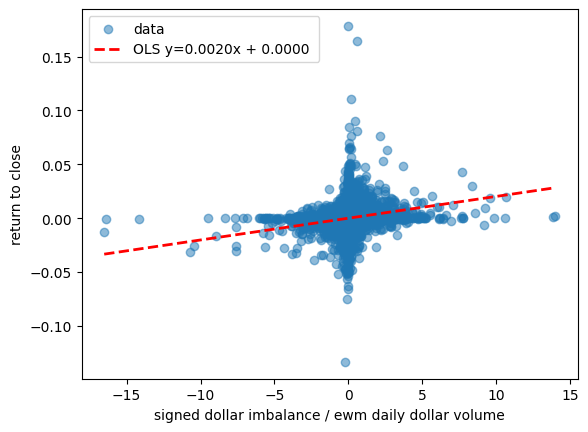

In [5]:
xs = np.linspace(np.min(X[:, 1]), np.max(X[:, 1])).clip()
plt.scatter(X[:, 1], y, alpha=0.5, label="data")
plt.plot(xs, res.params[1] * xs + res.params[0], label=f'OLS y={res.params[1]:,.4f}x + {res.params[0]:,.4f} ', color='red', linestyle='--', linewidth=2)
plt.xlabel("signed dollar imbalance / ewm daily dollar volume")
plt.ylabel("return to close")
plt.legend()
plt.show()

In [6]:
from scipy.stats import spearmanr

ic, pval = spearmanr(X[:, 1], y)
print(f"Spearman IC for ewm daily dollar volume: {ic:,.3f} with p-value: {pval:,.3f}")

Spearman IC for ewm daily dollar volume: 0.250 with p-value: 0.000


In [7]:
BETA_0, BETA_1 = res.params[0], res.params[1]

## Risk (Covariance) Model
Starting with a **SIMPLE** sample covariance of daily returns, filling null daily returns with the symbols **MEAN**.

Very much not a good enough covariance matrix yet.

In [16]:
daily_ret = (
    df_trades
    .select(["ts_event", "symbol", "price"])
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"])
    .agg(
        pl.col("price").last()
    )
    .with_columns(
        pl.col("price").pct_change().alias("ret")
    )
    .pivot(
        on="symbol",
        on_columns=data['symbol'].unique().to_list(),
        index="date",
        values="ret"
    )
    .with_columns(
        pl.all().fill_null(pl.all().mean())
    )
)

daily_ret = daily_ret.collect(engine="streaming")
daily_ret

date,NVDA,DKNG,PLTR,MSFT,RKLB,MELI,GOOG,GILD,AAPL,JD,ERIC,COIN,PEP,TSLA,INTC,QQQ,META,GOOGL,MRNA,IBIT,OKTA,TLT,MSTR,ZS,MRVL,TSLL,TSLQ,SBET,FBTC,AMD,GDS,SQQQ,MU,LI,AMZN,LOGI,…,NOVTU,LMRI,WLTH,MDLN,ASMU,DFTX,VISN,EQPT,XBCI,SHAZ,DMRA,VSNT,MWH,HBANZ,PAYP,ETHB,SWMR,XNDU,CSHR,HMH,KEEL,ARXS,ALMR,KLRA,TRAX,NHP,YSWY,XE,SPTX,COAG,SUJA,ODTX,BRUN,FRVO,CBRS,OCTV,BIDWU
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-07-25 00:00:00,9.339094,1.229622,0.353182,18.199925,-0.786149,101.28658,3.688164,2.085767,0.129613,4.346495,-0.879216,34.125561,10.069444,0.404122,0.114101,2.565565,155.687912,41.225137,-0.340672,0.168486,3.998023,26.434921,35.826146,3.163464,0.14983,3.820513,-0.859313,-0.08793,-0.818278,9.630907,-0.210425,-0.747929,2.07433,-0.27511,13.44819,-0.111361,…,2.45205,-0.164731,-0.19042,1.83348,0.266843,0.067741,-0.090842,0.563487,3.307713,1.65879,0.863695,0.445878,1.781099,0.163765,1.028768,0.359424,1.020226,-0.390809,-0.72755,0.235932,-0.823609,0.639282,0.009015,0.124649,-0.231008,-0.090913,-0.001524,0.14878,0.235959,0.686207,1.659165,0.113644,0.014529,1.605897,5.104974,-0.811578,-0.840627
2025-07-08 00:00:00,-0.292648,-0.163011,-0.191482,5.565499,6.74,375.591635,1.994529,12.952261,5.30243,-0.694413,-0.883333,10.768491,2.468911,9.850638,-0.021973,378.601375,15.837617,37.573009,2.087287,-0.673357,-0.020685,-0.165713,9.251421,18.158798,8.838577,-0.74154,-0.020833,-0.964523,3.091301,2.223106,0.277032,-0.608338,25.187368,-0.474474,11.371122,0.814255,…,2.45205,-0.164731,-0.19042,1.83348,0.266843,0.067741,-0.090842,0.563487,3.307713,1.65879,0.863695,0.445878,1.781099,0.163765,1.028768,0.359424,1.020226,-0.390809,-0.72755,0.235932,-0.823609,0.639282,0.009015,0.124649,-0.231008,-0.090913,-0.001524,0.14878,0.235959,0.686207,1.659165,0.113644,0.014529,1.605897,5.104974,-0.811578,-0.840627
2025-07-23 00:00:00,2.109776,8.327784,-0.372086,22.241617,10.251716,156.298949,68.963504,5.732662,-0.245865,26.489879,-0.934327,-0.445827,3.058217,1.30579,-0.753877,4.627046,17.351414,-0.486872,0.360817,1.180331,1.601469,2.163847,23.899879,5.274801,-0.212144,-0.961696,-0.575943,-0.50029,0.289224,-0.542711,5.858209,1.131488,2.59189,-0.845321,3.035891,7.084647,…,2.45205,-0.164731,-0.19042,1.83348,0.266843,0.067741,-0.090842,0.563487,3.307713,1.65879,0.863695,0.445878,1.781099,0.163765,1.028768,0.359424,1.020226,-0.390809,-0.72755,0.235932,-0.823609,0.639282,0.009015,0.124649,-0.231008,-0.090913,-0.001524,0.14878,0.235959,0.686207,1.659165,0.113644,0.014529,1.605897,5.104974,-0.811578,-0.840627
2025-09-02 00:00:00,0.710308,-0.729704,3.99142,363.6787,0.097729,23.52886,5.269822,8.708872,13.063667,0.841399,-0.74053,5.863215,2.043029,15.181774,-0.482091,75.231806,9.174118,8.171875,-0.314043,55.232143,1.90791,6.068923,180.230769,15.960173,1.223331,-0.534838,-0.774311,1.613846,4.307355,0.152399,-0.340004,-0.83468,-0.771911,0.605523,16.292402,3.930177,…,2.45205,-0.164731,-0.19042,1.83348,0.266843,0.067741,-0.090842,0.563487,3.307713,1.65879,0.863695,0.445878,1.781099,0.163765,1.028768,0.359424,1.020226,-0.390809,-0.72755,0.235932,-0.823609,0.639282,0.009015,0.124649,-0.231008,-0.090913,-0.001524,0.14878,0.235959,0.686207,1.659165,0.113644,0.014529,1.605897,5.104974,-0.811578,-0.840627
2025-10-28 00:00:00,1.511619,2.365011,1.826897,16.214864,10.414503,378.06457,4.627673,4.470534,0.311732,-0.500723,-0.08349,0.282245,3.171159,2.847536,2.108614,46.372006,8.6034,0.482376,0.893951,0.749051,0.060178,0.585832,8.529727,4.660186,23.709497,-0.246322,-0.801858,3.283489,23.499382,0.358058,-0.684798,-0.742786,8.002028,-0.716063,1.466222,1.050045,…,2.45205,-0.164731,-0.19042,1.83348,0.266843,0.067741,-0.090842,0.563487,3.307713,1.65879,0.863695,0.445878,1.781099,0.163765,1.028768,0.359424,1.020226,-0.390809,-0.72755,0.235932

In [18]:
cov_matrix = np.cov(daily_ret.to_numpy(), rowvar=False)
cov_matrix

array([[ 8.33079177e+25,  1.62836490e+11, -7.08835439e+12, ...,
        -4.84824924e+10, -2.35777552e+07, -8.08071951e+07],
       [ 1.62836490e+11,  4.94661533e+02, -3.29741183e+00, ...,
        -1.00424924e+00,  2.09514447e-03,  1.31926676e-03],
       [-7.08835439e+12, -3.29741183e+00,  4.03109370e+01, ...,
         1.41765123e-01,  9.41040279e-04,  1.80615289e-04],
       ...,
       [-4.84824924e+10, -1.00424924e+00,  1.41765123e-01, ...,
         2.60550600e+00, -7.10434482e-04, -4.08083681e-04],
       [-2.35777552e+07,  2.09514447e-03,  9.41040279e-04, ...,
        -7.10434482e-04,  6.77443015e-05,  4.65101059e-05],
       [-8.08071951e+07,  1.31926676e-03,  1.80615289e-04, ...,
        -4.08083681e-04,  4.65101059e-05,  4.85959498e-05]],
      shape=(1320, 1320))

## Daily MVO Optimizer

In [ ]:
import cvxpy as cp
# Parameters and variables
N = data['symbol'].n_unique()
lam = cp.Parameter(nonneg=True)
s = cp.Parameter(N, nonneg=True)
f = cp.Parameter(N)
p = cp.Variable(N)
p0 = 0.0

# The objective function
obj = 